In [ ]:
#读取和检查数据
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("equipment_defect_data.csv")

#将 df 表格中的 "Date"（日期）这一列，从“普通字符串（文本）格式”
#强制转换为“Pandas 标准的时间对象（Datetime）格式
df["Date"] = pd.to_datetime(df["Date"]) 
df.info() #快速查看整个 DataFrame 的“基本信息”和“健康状况”

df.head()

#按设备分组，比较 Defect Count
tool_summary = df.groupby("Tool_ID")["Defect_Count"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(tool_summary)

#按 Recipe 分组
recipe_summary = df.groupby("Recipe_ID")["Defect_Count"].agg(
    ["count", "mean", "std"]
)

print(recipe_summary)

#按 Lot 分组
lot_summary = df.groupby("Lot_ID").agg(
    {
        "Defect_Count": "mean",
        "Temperature": "mean",
        "Laser_Power": "mean"
    }
)

print(lot_summary)

#分析 Defect Count 和 Laser Power 的趋势
#经典的 "双 Y 轴（Dual Y-axis）折线图"
tool_b = df[df["Tool_ID"] == "Tool_B"] #从大表格中过滤出 Tool_B 这台机台的所有数据

fig, ax1 = plt.subplots(figsize=(12, 5)) #创建一个空白画布，并生成第一个坐标系 ax1（默认在左侧）
#ax1和ax2它们是完整的“坐标系（Axes 对象）”，不仅包含 Y 轴，还包含 X 轴、数据线、网格线、标题等所有元素
#当你调用 plt.subplots() 创建第一个坐标系时，Matplotlib 的默认规则是：把 Y 轴放在左边，X 轴放在底部

ax1.plot(
    tool_b["Date"],
    tool_b["Defect_Count"],
    marker="o",
    label="Defect Count"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Defect Count")

#建立第二个坐标系
ax2 = ax1.twinx() #.twinx()意思是“共享 X 轴（twin the x-axis）”

ax2.plot(
    tool_b["Date"],
    tool_b["Laser_Power"],
    marker="s",   #square表示数据点用小方块标出
    label="Laser Power"
)

ax2.set_ylabel("Laser Power")

plt.title("Tool_B: Defect Count vs Laser Power")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#按设备和 Recipe 组合比较Defect Count
tool_recipe_summary = df.groupby(
    ["Tool_ID", "Recipe_ID"]
)["Defect_Count"].mean().unstack() #魔法函数 .unstack()（重塑）
                                   #把最内层的索引（这里是 Recipe_ID）“拔”出来，横过来变成列名。
print(tool_recipe_summary)

In [3]:
#Python 计算控制限
import pandas as pd
import numpy as np

data = {
    "Laser_Power": [
        99.8, 100.2, 100.5, 99.9, 100.1,
        99.7, 100.3, 100.4, 99.8, 100.0,
        100.2, 99.9, 100.1, 100.4, 99.8
    ]
}

df = pd.DataFrame(data)

mean_value = df["Laser_Power"].mean()
std_value = df["Laser_Power"].std(ddof=1)

UCL = mean_value + 3 * std_value
CL = mean_value
LCL = mean_value - 3 * std_value

print("Mean:", mean_value)
print("Standard Deviation:", std_value)
print("UCL:", UCL)
print("CL:", CL)
print("LCL:", LCL)

#异常点识别（Out-of-Control Points）
df["Out_of_Control"] = (
    (df["Laser_Power"] > UCL) |
    (df["Laser_Power"] < LCL)
)

print(df)

#给异常点添加分类
df["Alarm"] = np.where(           #np.where(条件, 满足时的结果, 不满足时的结果)
    df["Laser_Power"] > UCL,
    "Above UCL",
    np.where(
        df["Laser_Power"] < LCL,
        "Below LCL",
        "Normal"
    )
)

print(df[["Laser_Power", "Alarm"]]) #打印DataFrame中的"Laser_Power"和"Alarm"这两列

Mean: 100.07333333333332
Standard Deviation: 0.2548575699334461
UCL: 100.83790604313366
CL: 100.07333333333332
LCL: 99.30876062353299
    Laser_Power  Out_of_Control
0          99.8           False
1         100.2           False
2         100.5           False
3          99.9           False
4         100.1           False
5          99.7           False
6         100.3           False
7         100.4           False
8          99.8           False
9         100.0           False
10        100.2           False
11         99.9           False
12        100.1           False
13        100.4           False
14         99.8           False
    Laser_Power   Alarm
0          99.8  Normal
1         100.2  Normal
2         100.5  Normal
3          99.9  Normal
4         100.1  Normal
5          99.7  Normal
6         100.3  Normal
7         100.4  Normal
8          99.8  Normal
9         100.0  Normal
10        100.2  Normal
11         99.9  Normal
12        100.1  Normal
13        100.4  N

CL: 100.01
UCL: 100.6174537019395
LCL: 99.40254629806051
                  Time  Laser_Power
13 2026-11-01 13:00:00        100.7
14 2026-11-01 14:00:00        100.9
15 2026-11-01 15:00:00        101.1
16 2026-11-01 16:00:00        101.3
17 2026-11-01 17:00:00        101.5
18 2026-11-01 18:00:00        101.4
19 2026-11-01 19:00:00        101.6
20 2026-11-01 20:00:00        101.8
21 2026-11-01 21:00:00        102.0
22 2026-11-01 22:00:00        102.1
23 2026-11-01 23:00:00        102.3
24 2026-11-02 00:00:00        102.5
                  Time  Laser_Power  Rule_1  Trend_Up  Trend_Down  Shift_Up  \
13 2026-11-01 13:00:00        100.7    True     False       False     False   
14 2026-11-01 14:00:00        100.9    True     False       False     False   
15 2026-11-01 15:00:00        101.1    True     False       False     False   
16 2026-11-01 16:00:00        101.3    True     False       False      True   
17 2026-11-01 17:00:00        101.5    True      True       False      True   
1

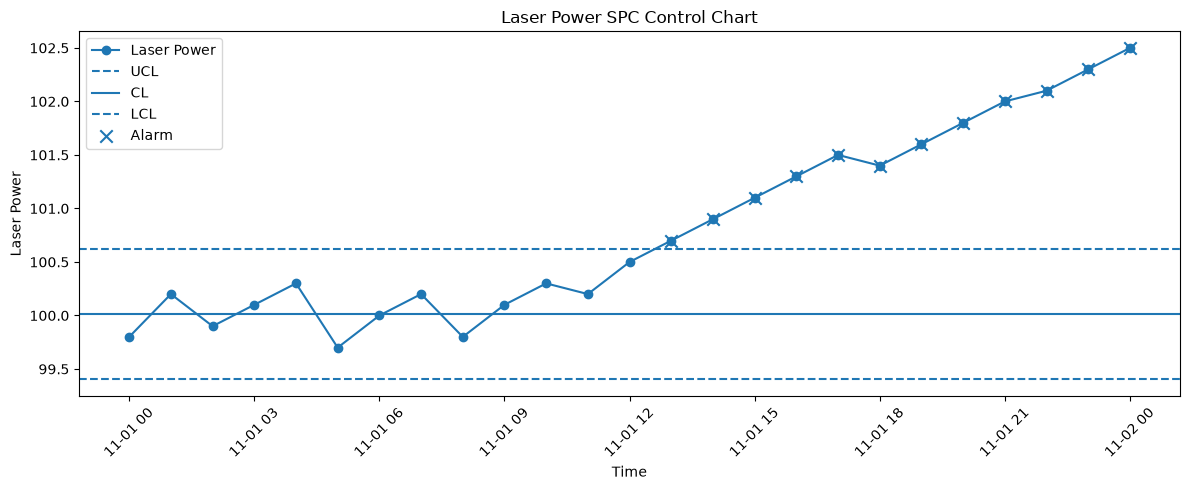

In [13]:
#使用 Python 建立完整的 SPC 分析程序
#Step 1：准备数据
#引入数据分析必备的三个库
import pandas as pd  #pd 处理表格
import numpy as np   #np 处理数学计算
import matplotlib.pyplot as plt #plt 用来画图

data = {
    "Time": pd.date_range(  #用 Pandas 的 date_range() 函数，瞬间生成一列标准的时间序列
        start="2026-11-01", #从 2026 年 11 月 1 日 0 点开始
        periods=25,         #连续生成 25 个时间点
        freq="h"            #频率为每小时（hour）
    ),
    "Laser_Power": [        #手动输入功率数据
        99.8, 100.2, 99.9, 100.1, 100.3,
        99.7, 100.0, 100.2, 99.8, 100.1,
        100.3, 100.2, 100.5, 100.7, 100.9,
        101.1, 101.3, 101.5, 101.4, 101.6,
        101.8, 102.0, 102.1, 102.3, 102.5
    ]
}

df = pd.DataFrame(data) #构建 DataFrame
#把刚才建好的字典（包含 Time 和 Laser_Power 两个列表）变成一个漂亮的二维表格 df

#print(df.head()) #会显示一个纯文本、没有边框的“白底黑字”表格
df.head()         #会显示一个带边框、排版美观的表格

#Step 2：计算控制限
baseline = df.iloc[:10]["Laser_Power"] #提取基线数据（Baseline）
#df.iloc[:10]：iloc 是基于位置的索引。[:10] 意思是提取表格的第 0 行到第 9 行（共 10 行）

mean_value = baseline.mean() #算出这前 10 个数据的平均值
std_value = baseline.std(ddof=1) #计算样本标准差（分母是 n-1，代表无偏估计）

#计算控制限（3σ 原则）
CL = mean_value       #CL（中心线）：直接等于均值
UCL = mean_value + 3 * std_value
LCL = mean_value - 3 * std_value

print("CL:", CL)
print("UCL:", UCL)
print("LCL:", LCL)

#Step 3：识别超过控制限的点(Out of Control Point)
#找出超限的点
df["Above_UCL"] = df["Laser_Power"] > UCL
df["Below_LCL"] = df["Laser_Power"] < LCL

#逻辑合并：定义规则1
df["Rule_1"] = (
    df["Above_UCL"] | df["Below_LCL"]
)

print(
    df.loc[            #df.loc[行条件, 列清单]
        df["Rule_1"],  #行条件：满足df["Rule_1"]这个条件的选出来
        ["Time", "Laser_Power"] #列清单：只提取“时间”和“激光功率”这两列来展示
    ]
)

#Step 4：识别连续上升或下降，计算相邻两点的差值（差分）
df["Change"] = df["Laser_Power"].diff() #diff()：计算当前行减去上一行的值

df["Increasing"] = df["Change"] > 0 #如果 Change 大于 0，Increasing 列为 True（说明功率在上升）
df["Decreasing"] = df["Change"] < 0 #如果 Change 小于 0，Decreasing 列为 True（说明功率在下降）

# 处理趋势向上的预警
df["Trend_Up"] = (
    df["Increasing"]   # 找出刚才标记为上升（True）的点
    .rolling(window=6) # 开一个大小为 6 的滑动窗口
    .sum() == 6        # 算这 6 个窗口里的总和，看是否等于 6
)                      # 在 Python 计算时，True 相当于 1，False 相当于 0
                       #如果 6 个点都在上升，总和就是 1+1+1+1+1+1 = 6。此时 == 6 成立，返回 True（触发预警）
# 处理趋势向下的预警
df["Trend_Down"] = (
    df["Decreasing"]
    .rolling(window=6)
    .sum() == 6
)
#df["Trend_Up"]

#Step 5：识别连续 8 个点在中心线同一侧
df["Above_CL"] = df["Laser_Power"] > CL
df["Below_CL"] = df["Laser_Power"] < CL

df["Shift_Up"] = (
    df["Above_CL"]
    .rolling(window=8)
    .sum() == 8
)

df["Shift_Down"] = (
    df["Below_CL"]
    .rolling(window=8)
    .sum() == 8
)

#Step 6：汇总报警
df["Alarm"] = (
    df["Rule_1"] |         # 规则1：超出 3σ 控制界限（超出控制限的点）
    df["Trend_Up"] |       # 趋势：连续 6 点上升
    df["Trend_Down"] |     # 趋势：连续 6 点下降
    df["Shift_Up"] |       # 链：连续 8 点在中心线上方
    df["Shift_Down"]       # 链：连续 8 点在中心线下方
)

print(
    df.loc[                #.loc[行条件, 列清单]
        df["Alarm"],       #行条件：df["Alarm"]（只提取综合报警为 True 的行）
        [
            "Time",
            "Laser_Power",
            "Rule_1",
            "Trend_Up",
            "Trend_Down",
            "Shift_Up",
            "Shift_Down"
        ]
    ]
)

#Step 7：绘制 SPC 控制图
plt.figure(figsize=(12, 5)) #创建一个 12x5 的画布

plt.plot(        #把时间和激光功率用实线连接起来，并在每个数据点上画一个小圆圈（marker="o"）
    df["Time"],         # x（时间）
    df["Laser_Power"],  # y（功率）
    marker="o",         # 用圆圈标记
    label="Laser Power" # 图例名字
)

#绘制三条控制参考线
#画出控制上限（UCL）、中心线（CL）和控制下限（LCL）
plt.axhline(UCL, linestyle="--", label="UCL") # 画“水平参考线”，Axis Horizontal Line（水平轴线）
#plt.axhline(y, **样式参数)，不需要填 X 轴数据，因为它是贯穿全图的
plt.axhline(CL, linestyle="-", label="CL")

plt.axhline(LCL, linestyle="--", label="LCL")

alarm_df = df[df["Alarm"]] #提取异常数据
#把前面算出来的 df["Alarm"] 为 True（触发了任何报警规则）的行全部单独拎出来，存入一个小表格 alarm_df 中

#在图上高亮标出异常点
plt.scatter(             #plt.scatter：散点图函数，专门用来在特定的 (X, Y) 坐标上打点
    alarm_df["Time"],        #X轴数据
    alarm_df["Laser_Power"], #Y轴数据
    marker="x",          #标记形状为大叉号（X），代表“错误/异常”
    s=80,     #标记的尺寸大小（size），80 算是比较大的，确保红叉能醒目地覆盖在原来的圆圈折线上
    label="Alarm"
)
#效果：你会看到一条正常的折线图上，突然在几个特定位置出现了巨大的“X”标志，一目了然。

plt.title("Laser Power SPC Control Chart")
plt.xlabel("Time")
plt.ylabel("Laser Power")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()